# Практическая работа №1: Линейные дискретные системы и преобразование Фурье

Выполнил студент гр. 3381 Гладилин Евгений Олегович. Вариант №3.

## Цель работы

 Изучить математическое описание линейных дискретных систем и дискретного преобразования Фурье (ДПФ) периодических последовательностей и последовательностей конечной длины.

## Основные теоретические положения

Разностное уравнение рекурсивного звена 2-го порядка связывает текущий отсчет выхода с текущим и предыдущими отсчетами входа и предыдущими отсчетами выхода:
$$
y(n) = b_0 x(n) + b_1 x(n-1) + b_2 x(n-2) - a_1 y(n-1) - a_2 y(n-2)
$$

Импульсная характеристика \(h(n)\) вычисляется при подаче на вход единичного импульса (при нулевых начальных условиях). Первые три отсчета формируются с учетом коэффициентов \(b_i\), а начиная с \(n=3\) — только за счет рекурсии:
$$
h(0) = b_0, \quad h(1) = b_1 - a_1 h(0), \quad h(2) = b_2 - a_1 h(1) - a_2 h(0)
$$
$$
h(n) = -a_1 h(n-1) - a_2 h(n-2), \quad n \ge 3
$$


Реакция системы \(y(n)\) на произвольное воздействие \(x(n)\) вычисляется по формуле линейной свёртки:
$$
y(n) = \sum_{k} x(k) h(n-k)
$$
Длина свёртки двух последовательностей определяется как \(N_y = N_x + N_h - 1\).

Передаточная функция дискретной системы \(H(z)\) представляет собой отношение Z-преобразований выхода и входа:
$$
H(z) = \frac{b_0 + b_1 z^{-1} + b_2 z^{-2}}{a_0 + a_1 z^{-1} + a_2 z^{-2}}
$$
Нули и полюсы передаточной функции находятся как корни числителя и знаменателя соответственно:
$$
z_{1,2} = \frac{-b_1 \pm \sqrt{b_1^2 - 4 b_0 b_2}}{2 b_0}, \quad p_{1,2} = \frac{-a_1 \pm \sqrt{a_1^2 - 4 a_0 a_2}}{2 a_0}
$$
Комплексные числа могут быть записаны в алгебраической форме \(z = x + jy\) или в показательной \(z = r e^{j\theta}\), где \(r = \sqrt{x^2 + y^2}\), а \(\theta = \operatorname{arctg}(y/x)\). Передаточная функция в виде произведения простейших множителей записывается как:
$$
H(z) = K \frac{(1 - z_1 z^{-1})(1 - z_2 z^{-1})}{(1 - p_1 z^{-1})(1 - p_2 z^{-1})}
$$
Устойчивость рекурсивного звена гарантируется, если все полюсы лежат внутри единичной окружности, то есть \(|p_i| < 1\).

Частотные характеристики (АЧХ и ФЧХ) получаются путем подстановки \(z = e^{j\hat{\omega}}\) в передаточную функцию:
$$
H(e^{j\hat{\omega}}) = H(z)\big|_{z=e^{j\hat{\omega}}}
$$
Связь нормированной угловой частоты \(\hat{\omega}\) с физической частотой \(f\) (Гц) при частоте дискретизации \(f_д\):
$$
\hat{\omega} = 2\pi \frac{f}{f_д} \quad \Rightarrow \quad f = \frac{\hat{\omega} f_д}{2\pi}
$$
Основная полоса частот ограничена интервалом \(0 \le \hat{\omega} \le \pi\) (или \(0 \le f \le f_д/2\)).

Прямое дискретное преобразование Фурье (ДПФ) конечной последовательности длины \(N\):
$$
X(k) = \sum_{n=0}^{N-1} x(n) e^{-j \frac{2\pi}{N} k n}
$$
Обратное дискретное преобразование Фурье (ОДПФ):
$$
x(n) = \frac{1}{N} \sum_{k=0}^{N-1} X(k) e^{j \frac{2\pi}{N} k n}
$$
Связь модуля ДПФ с амплитудным спектром периодической последовательности выражается через нормировку на длину периода:
$$
X_{period}(k) = \frac{|X(k)|}{N}
$$

Восстановление периодического аналогового сигнала \(x(t)\) по отсчетам ДПФ \(X(k)\) производится по формуле:
$$
x(t) = \frac{1}{N} \sum_{k=-N/2}^{N/2-1} X_a(k) \exp\left( j\frac{2\pi}{NT} kt \right)
$$
где отсчеты \(X_a(k)\) связаны с отсчетами ДПФ \(X(k)\) соотношением:
$$
X_a(k) =
\begin{cases}
X(N + k), & -N/2 \leqslant k \leqslant -1 \\
X(k), & 0 \leqslant k \leqslant N/2 - 1
\end{cases}
$$

Теорема Парсеваля устанавливает равенство между энергией сигнала и энергией его спектра:
$$
\sum_{n=0}^{N-1} |x(n)|^2 = \frac{1}{N} \sum_{k=0}^{N-1} |X(k)|^2
$$

## Постановка задачи

Выполнить программную реализацию линейных дискретных систем, а также применить ДПФ для анализа периодических последовательностей и последовательностей конечной длины. Полученные результаты содержательно проинтерпретировать.

## Выполнение работы



In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import lfilter, freqz

### Часть 1

#### Константы для варианта №3

$N_{вар} = 3$

$b_0 = 0.56,\ b_1 = 0.579936,\ b_2 = 0.784$

$a_0 = 1,\ a_1 = -0.8528,\ a_2 = 0.658$

$N_1 = 23,\ N_2 = 33,\ f_Д = 3000$

#### 1.1 Вычислить импульсную характеристику длины N1 по заданной передаточной функции с коэффициентами bi,ak и построить её график. Записать аналитическую формулу импульсной характеристики рекурсивного звена 2-го порядка с учетом нулевых начальных условий. Пояснить, чему в действительности равна длина импульсной характеристики.

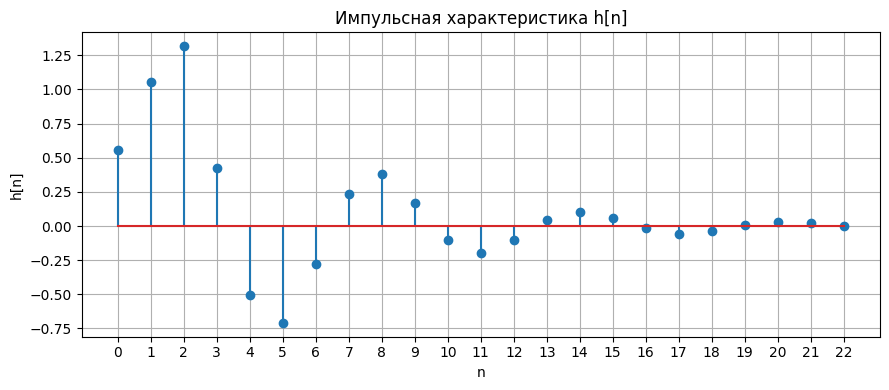

In [61]:
b0 = 0.56
b1 = 0.579936
b2 = 0.784
a0 = 1
a1 = -0.8528
a2 = 0.658
N1 = 23
N2 = 33
fd = 3000
b = np.array([b0,b1,b2])
a = np.array([a0,a1,a2])

imp = np.r_[1. , np.zeros(N1-1)] # Импульсная характеристика
h = lfilter(b, a, imp)
n = np.arange(N1)

plt.figure(figsize=(9, 4))
plt.stem(n, h)
plt.grid(True)
plt.xlabel("n")
plt.ylabel("h[n]")
plt.title("Импульсная характеристика h[n]")
plt.xticks(n)
plt.tight_layout()
plt.show()

Аналитическая формула импульсной характеристики рекурсивного звена 2-го порядка

$h(n) = b_0 \cdot u_0(n) + b_1 \cdot u_o(n-1) + b_2 \cdot u_o(n-2) - a_1 \cdot h_o(n-1) - a_2 \cdot h_o(n-2)$

\
При нулевых начальных условиях h(n) = 0 для n < 0:

$h(0) = b_0 \cdot u_0(0) = b_0$

$h(1) = b_1 \cdot u_o(0) - a_1 \cdot h(0)$

$h(2) = b_2 \cdot u_o(0) - a_1 \cdot h(1) - a_2 \cdot h(0)$

$h(3) = -a_1 \cdot h(2) - a_2 \cdot h(1)$

То есть, из-за ненулевых коэффициентов $a_i$ и рекурсивно заданной формулы следующие значения будут зависеть от двух предыдущих. То есть это БИХ и его длина бесконечна.

#### 1.2 Вычислить реакцию $y_1(n)$ по формуле свёртки. В качестве воздействия x(n) длины $N_2$ выбрать дискретный прямоугольный импульс:
$
x(n) =
\begin{cases}
1, & 0 \leqslant n < int(N_2/2) \\
0, & int(N_2/2) \leqslant n \leqslant N_2 - 1
\end{cases}
$

где функция int(t) – округление до ближайшего целого. Вывести графики воздействия и реакции. Пояснить:

* a чему равна длина импульса x;
* b чему равна длина свёртки аналитически и по графику;
* c почему её ограничивают до длины воздействия.


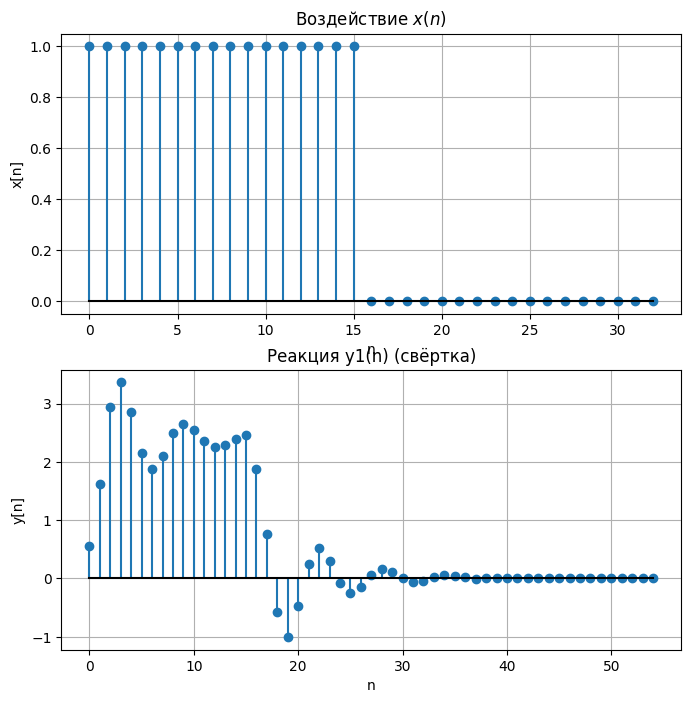

In [ ]:
# Воздействие x(n) (прямоугольный импульс)
x = np.zeros(N2)
x[:int(N2 / 2)] = 1.0

# Вычисление реакции y1(n) по формуле свёртки
y1 = np.convolve(h, x)

fig, ax = plt.subplots(2, 1, figsize=(8, 8))

# График x(n)
ax[0].stem(np.arange(N2), x, basefmt="k-")
ax[0].set_title('Воздействие $x(n)$')
ax[0].set_xlabel('n')
ax[0].set_ylabel('x[n]')
ax[0].grid(True)

# График y1(n)
ax[1].stem(np.arange(len(y1)), y1, basefmt="k-")
ax[1].set_title('Реакция y1(n) (свёртка)')
ax[1].set_xlabel('n')
ax[1].set_ylabel('y[n]')
ax[1].grid(True)

* a) Длина импульса x равна 33. При n $\in$ [0,15] x = 1, при n $\in$ [16,32] x = 0
* b) Длина свёртки аналитически вычисляется по формуле $N_y = N_x + N_h - 1 = N_2 + N_1 - 1 = 55$. По графику значения становятся равны нулю с n = 40.
* c) Свёртку ограничивают до длины воздействия, чтобы рассматривать реакцию сигнала на интервале воздействия.


#### 1.3 Вычислить реакцию $y_2$(n) по разностному уравнению. Задать воздействие x(n) из п. 2. Вывести графики воздействия и реакции. Сравнить графики реакций $y_1$(n) и $y_2$(n). Записать разностное уравнение рекурсивного звена 2-го порядка с заданными коэффициентами. Пояснить, чему равны длины воздействия и реакции.

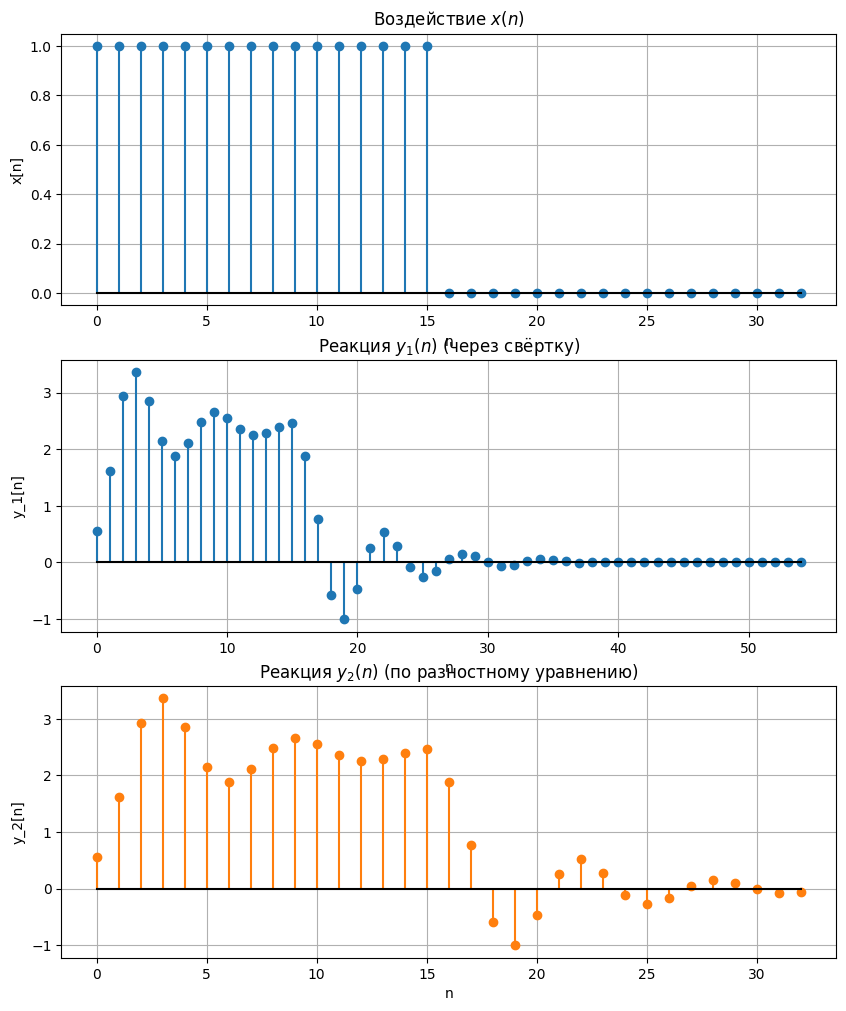

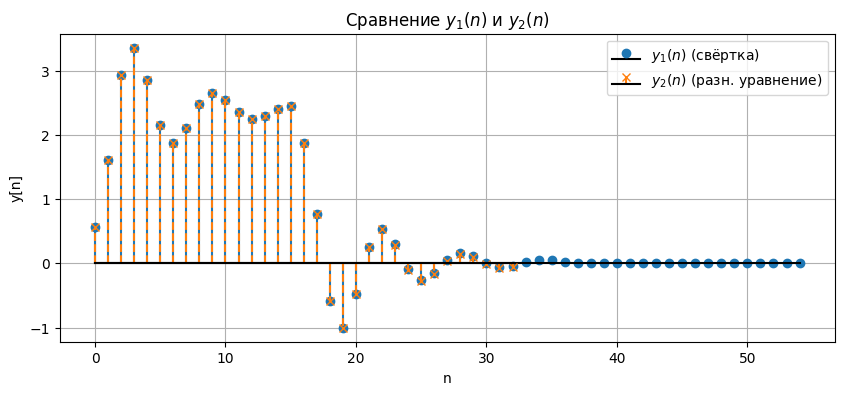

In [ ]:
y2 = lfilter(b, a, x) # Реакция по разностному уравнению

fig, ax = plt.subplots(3, 1, figsize=(10, 12))

# График x(n)
ax[0].stem(np.arange(N2), x, basefmt="k-")
ax[0].set_title('Воздействие $x(n)$')
ax[0].set_xlabel('n'); ax[0].set_ylabel('x[n]')
ax[0].grid(True)

# График y1(n) (свёртка)
ax[1].stem(np.arange(len(y1)), y1, linefmt='C0-', markerfmt='C0o', basefmt="k-")
ax[1].set_title('Реакция $y_1(n)$ (через свёртку)')
ax[1].set_xlabel('n'); ax[1].set_ylabel('y_1[n]')
ax[1].grid(True)

# График y2(n) (разностное уравнение)
ax[2].stem(np.arange(len(y2)), y2, linefmt='C1-', markerfmt='C1o', basefmt="k-")
ax[2].set_title('Реакция $y_2(n)$ (по разностному уравнению)')
ax[2].set_xlabel('n'); ax[2].set_ylabel('y_2[n]')
ax[2].grid(True)

# График сравнения y1(n) и y2(n)
plt.figure(figsize=(10, 4))
plt.stem(np.arange(len(y1)), y1, linefmt='C0-', markerfmt='C0o', basefmt="k-", label='$y_1(n)$ (свёртка)')
plt.stem(np.arange(len(y2)), y2, linefmt='C1--', markerfmt='C1x', basefmt="k-", label='$y_2(n)$ (разн. уравнение)')
plt.title('Сравнение $y_1(n)$ и $y_2(n)$')
plt.xlabel('n'); plt.ylabel('y[n]')
plt.legend()
plt.grid(True)

Разностное уравнение рекурсивного звена 2-го порядка:

$$y(n) = \sum_{k=0}^{2}b_k \cdot x(n-k) - \sum_{k=1}^2a_k \cdot y(n-k)$$
$y(n) = 0.56 x(n) + 0.579936 x(n-1) + 0.784x(n-2) + 0.8528 y(n-1) - 0.658y(n-2)$

Графики реакций полученные через свёртку ($y_1$) и через разностное уравнение ($y_2$) совпали по графикам. Длина воздействия x(n) равна 33, $y_2$ = 33, длина $y_1$ = 55. То есть разностное уравнение вычисляет реакцию только на промежутке равном длине входного сигнала, свёртка вычисляет реакцию часть после конца входного сигнала.

#### 1.4 Вычислить нули и полюсы передаточной функции. нули и полюсы в алгебраической и показательной формах и пояснить связь между ними. Выразить значение аргумента полюса и нуля относительно π. Представить передаточную функцию в виде произведения простейших множителей с нулями и полюсами в показательной форме.

In [ ]:
zeros = np.roots(b)
poles = np.roots(a)
c = 0

print("Нули:")
for z in zeros:
  r = np.abs(z) # Модуль
  phi = np.angle(z) # Аргумент в радианах
  c+=1
  print(f"Ноль №{c}:")
  print(f"Алгебраическая форма:{round(z.real,3)} + {round(z.imag,3)}j")
  print(f"Показательная форма: {round(r,3)} * exp(j * {round(phi,3)})")
  print(f"Аргумент отн. π:     {round(phi/np.pi,3)} * π\n")

c = 0
print("\n\nПолюсы")
for p in poles:
  r = np.abs(p)
  phi = np.angle(p)
  c+=1
  print(f"Полюс №{c}:")
  print(f"Алгебраическая форма:{round(p.real,3)} + {round(p.imag,3)}j")
  print(f"Показательная форма: {round(r,3)} * exp(j * {round(phi,3)})")
  print(f"Аргумент отн. π:     {round(phi/np.pi,3)} * π\n")

Нули:
Ноль №1:
Алгебраическая форма:-0.518 + 1.064j
Показательная форма: 1.183 * exp(j * 2.024)
Аргумент отн. π:     0.644 * π

Ноль №2:
Алгебраическая форма:-0.518 + -1.064j
Показательная форма: 1.183 * exp(j * -2.024)
Аргумент отн. π:     -0.644 * π



Полюсы
Полюс №1:
Алгебраическая форма:0.426 + 0.69j
Показательная форма: 0.811 * exp(j * 1.017)
Аргумент отн. π:     0.324 * π

Полюс №2:
Алгебраическая форма:0.426 + -0.69j
Показательная форма: 0.811 * exp(j * -1.017)
Аргумент отн. π:     -0.324 * π



Алгебраическая форма записи (x + jy) - показывает проекцию комплексного числа на действительную и мнимую оси. Показательная ($r \cdot e^{j\varphi}$) - это длина вектора и его поворот.

Связь между алгебраической и показательной формами:

$r = \sqrt{x^2+y^2}, \ \ \varphi = arg(z) = arctg{\frac{y}{x}}, \ \ x = r \cdot cos(\varphi), \ \  y = r \cdot sin (\varphi)$

Передаточная функция:

$$H(z) = 0.56 \cdot \frac{(1 - 1.183 e^{0.644j\pi} z^{-1})(1 - 1.183 e^{- 0.644j\pi} z^{-1})}{(1 - 0.811 e^{0.676j\pi} z^{-1})(1 - 0.811 e^{-0.676j\pi} z^{-1})} = 0.56 \cdot \frac{1 - 2 \cdot 1.183 \cos(0.644\pi) z^{-1} + 1.183^2 z^{-2}}{1 - 2 \cdot 0.811 \cos(0.676\pi) z^{-1} + 0.811^2 z^{-2}} = \frac{ 0.56 + 0.579936\cdot z^{-1} + 0.784\cdot z^{-2}}{1 -0.8528 \cdot z^{-1}+ 0.658 \cdot z^{-2}}$$

Полученные коэффициенты при умножении на сопряженное равны начальным коэффициентам $a_i, b_k$

#### 1.5 Изобразить карту нулей и полюсов. Пояснить:
* a. является ли рекурсивное звено устойчивым;
* b. совпадают ли значения нулей и полюсов с вычисленными в п. 4.

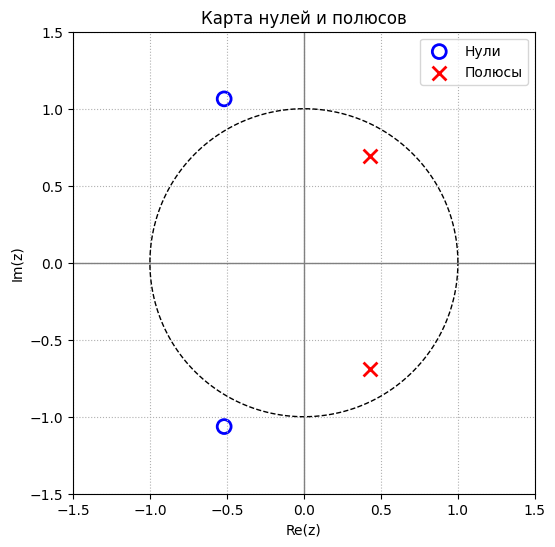

In [42]:
plt.figure(figsize=(6, 6))

varphi = np.linspace(0, 2*np.pi, 400)
plt.plot(np.cos(varphi), np.sin(varphi), 'k--', linewidth=1)

# Нули и полюсы
plt.axhline(0, color='gray', linewidth=1)
plt.axvline(0, color='gray', linewidth=1)
plt.scatter(zeros.real, zeros.imag, marker='o', s=100, facecolors='none', edgecolors='blue', linewidth=2, label='Нули')
plt.scatter(poles.real, poles.imag, marker='x', s=100, color='red', linewidth=2, label='Полюсы')

plt.gca().set_aspect('equal', adjustable='box')
plt.grid(True, linestyle=':')
plt.xlim(-1.5, 1.5)
plt.ylim(-1.5, 1.5)
plt.xlabel('Re(z)')
plt.ylabel('Im(z)')
plt.title('Карта нулей и полюсов')
plt.legend(loc='upper right')

* a. Звено является устойчивым, так как полюса лежат внутри единичной окружности в комплексной плоскости
* b. Значения совпадают.

#### 1.6 Вычислить амплитудно-частотную (АЧХ) и фазочастотную (ФЧХ) характеристики в шкале нормированных частот $\hat ω$ и вывести их графики. Пояснить:
* a. чему равны границы основной полосы частот;
* b. соответствие между картой нулей и полюсов и видом АЧХ;
* c. какому значению АЧХ соответствует скачок на π, если он имеется;
* d. какие частотные составляющие воздействия, низкие или высокие, оказались преимущественно подавленными в реакции.

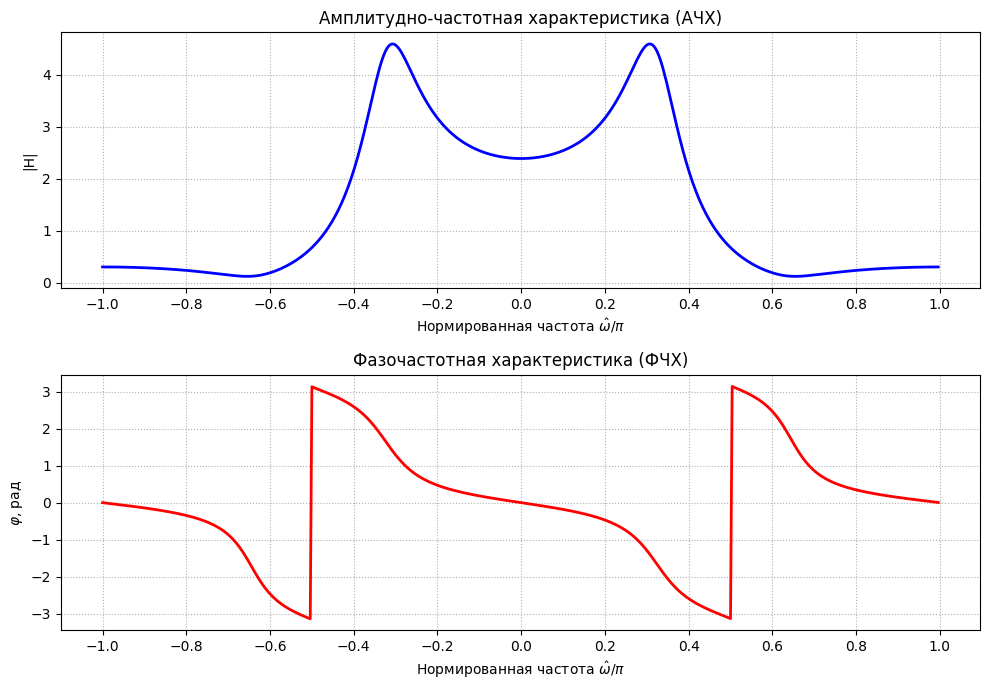

In [72]:
w, H = freqz(b, a, worN=512, whole=True)

# Перенос нулевой частоты в центр (диапазон от -π до π)
w = np.fft.fftshift(w)
H = np.fft.fftshift(H)

# Преобразование частот (чтобы на графике было от -π до π)
w = np.where(w >= np.pi, w - 2*np.pi, w)

fig, ax = plt.subplots(2, 1, figsize=(10, 7))

# АЧХ
ax[0].plot(w/np.pi, np.abs(H), 'b-', linewidth=2)
ax[0].set_xlabel(r'Нормированная частота $\hat{\omega} / \pi$')
ax[0].set_ylabel('|H|')
ax[0].set_title('Амплитудно-частотная характеристика (АЧХ)')
ax[0].grid(True, linestyle=':')
ax[0].set_xticks(np.arange(-1, 1.1, 0.2))

# ФЧХ
ax[1].plot(w/np.pi, np.angle(H), 'r-', linewidth=2)
ax[1].set_xlabel(r'Нормированная частота $\hat{\omega} / \pi$')
ax[1].set_ylabel(r'$\varphi$, рад')
ax[1].set_title('Фазочастотная характеристика (ФЧХ)')
ax[1].grid(True, linestyle=':')
ax[1].set_xticks(np.arange(-1, 1.1, 0.2))

plt.tight_layout()

* a. Границы основной полосы - [0, $\pi$]. Границы нормированных частот $-\pi\le \hat\omega < \pi$. На графике значения на оси абсцисс разделены на $\pi$.
* b. У АЧХ есть два максимума, которые существуют при частотах +-0.3$\pi$, на карте полюсов и нулей полюсы +-0.324π. То есть полюсы соответствуют максимумам в АЧХ. Минимумы на графике АЧХ наблюдаются при значениях +-0.65$\pi$, нули равны +-0.644π, значит нули соответсвуют минимумам АЧХ.
* c. Скачки фаз на $\pi$ происходят при значениях +-0,5$\pi$.
* d. Данный фильтр заглушает высокие частоты (нормированные равные +-$\pi$), слабее для низких частот из нормированного диапазона [-0.2π, 0.2π], почти не заглушает средние частоты в диапазонах [-0.4π, -0.2π] и [0.2π, 0.4π].

#### 1.7 Вычислить АЧХ и ФЧХ в шкале частот f(Гц) при заданной частоте дискретизации $f_д$ и вывести их графики. Пояснить:
* чему равны границы основной полосы частот;
* соответствие частотами $\hat\omega$ и $f$.

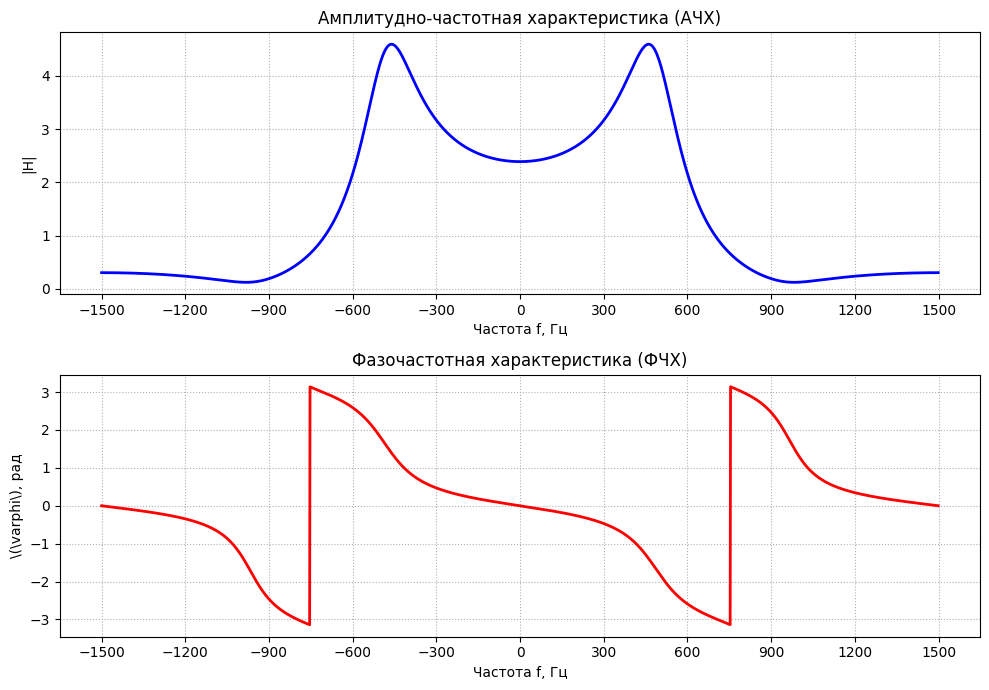

In [62]:
f = (w / np.pi) * (fd / 2)

fig, ax = plt.subplots(2, 1, figsize=(10, 7))

# АЧХ
ax[0].plot(f, np.abs(H), 'b-', linewidth=2)
ax[0].set_xlabel('Частота f, Гц')
ax[0].set_ylabel('|H|')
ax[0].set_title('Амплитудно-частотная характеристика (АЧХ)')
ax[0].grid(True, linestyle=':')
ax[0].set_xticks(np.arange(-1500, 1501, 300))

# ФЧХ
ax[1].plot(f, np.angle(H), 'r-', linewidth=2)
ax[1].set_xlabel('Частота f, Гц')
ax[1].set_ylabel(r'$\varphi$, рад')
ax[1].set_title('Фазочастотная характеристика (ФЧХ)')
ax[1].grid(True, linestyle=':')
ax[1].set_xticks(np.arange(-1500, 1501, 300))

plt.tight_layout()

* a. Основная полоса частот от 0 до $\frac{f_д}{2}$, то есть это диапазон [0, 1500 Гц]
* b. Соответствие частот дискретизации и нормированных:
$$\hat\omega = \cfrac{\omega}{\pi} = 2 \cfrac{f}{f_д} ⇒ f = \cfrac{\hat\omega \cdot f_д}{2}$$


### Часть 2

#### Константы для варианта №3
$N_{вар} = 3,  N = 64, f_д = 6000, T = \cfrac{1}{6000}$

$A_1 = 1.03, A_2 = 2.06, f_1 = 750, f_2 = 1125$

#### 2.1 Вывести графики последовательности x(n) на периоде N в шкале дискретного и дискретного нормированного времени:

$$x(nT) = A_1 \cos\left(2\pi f_1 n T + \frac{\pi}{4}\right) + A_2 \cos\left(2\pi f_2 n T + \frac{\pi}{8}\right)$$

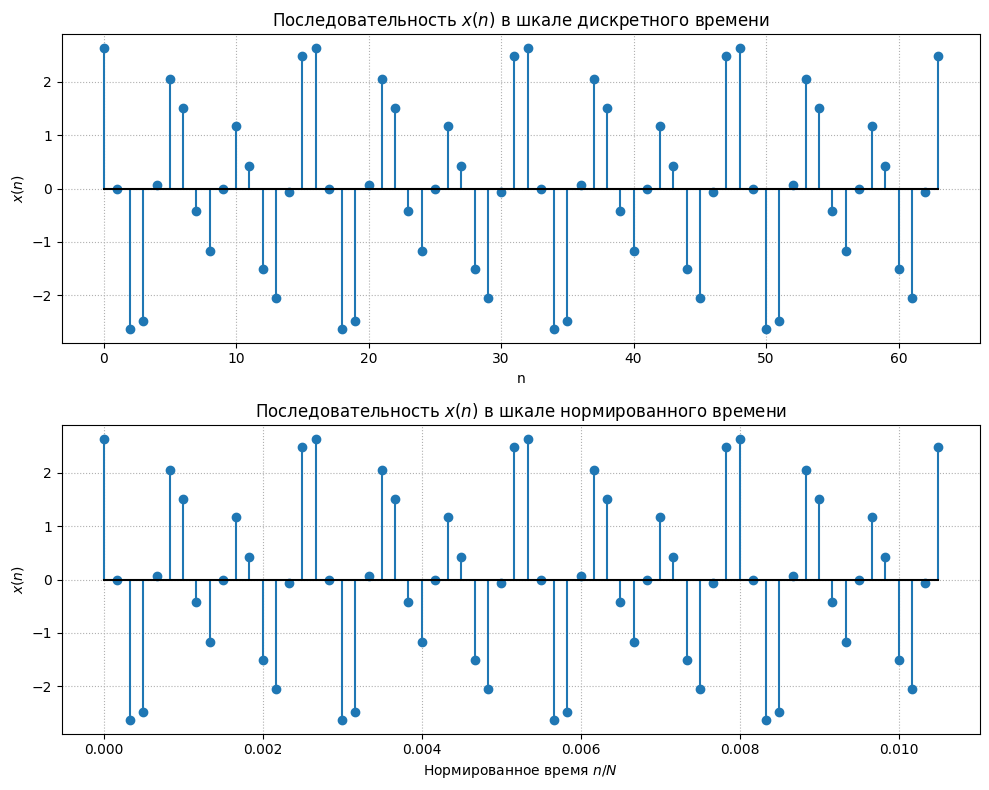

In [70]:
N = 64
fd = 6000
T = 1.0 / fd
A1 = 1.03
A2 = 2.06
f1 = 750.0
f2 = 1125.0

n = np.arange(0, N)

# Последовательность x(nT)
x1 = A1 * np.cos(2 * np.pi * f1 * n * T + np.pi / 4)
x2 = A2 * np.cos(2 * np.pi * f2 * n * T + np.pi / 8)
xn = x1 + x2

fig, ax = plt.subplots(2, 1, figsize=(10, 8))

ax[0].stem(n, xn, basefmt="k-")
ax[0].set_title('Последовательность x(n) в шкале дискретного времени')
ax[0].set_xlabel('n')
ax[0].set_ylabel('$x(n)$')
ax[0].grid(True, linestyle=':')

ax[1].stem(n*T, xn, basefmt="k-")
ax[1].set_title('Последовательность x(n) в шкале нормированного времени')
ax[1].set_xlabel('Нормированное время n/N')
ax[1].set_ylabel('x(n)')
ax[1].grid(True, linestyle=':')

plt.tight_layout()

#### 2.2 Вычислить ОДПФ от ДПФ последовательности x(n) и вывести график полученной последовательности в шкале дискретного нормированного временах.

/usr/local/lib/python3.13/dist-packages/matplotlib/cbook.py:1709: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/usr/local/lib/python3.13/dist-packages/numpy/ma/core.py:3452: ComplexWarning: Casting complex values to real discards the imaginary part
  _data[indx] = dval
/usr/local/lib/python3.13/dist-packages/matplotlib/cbook.py:1345: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


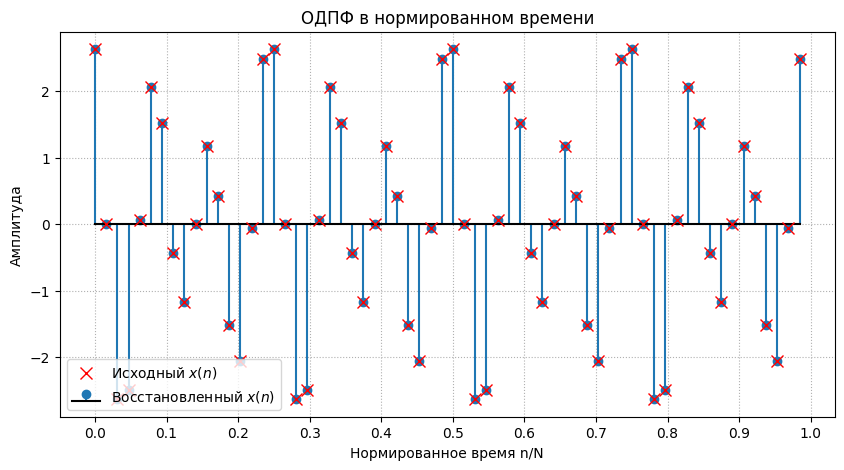

In [89]:
X = np.fft.fft(xn)
x_o = np.fft.ifft(X)

plt.figure(figsize=(10, 5))

plt.stem(n / N, x_o, basefmt="k-", label='Восстановленный $x(n)$')

# Исходный сигнал
plt.plot(n / N, xn, 'rx', markersize=8, label='Исходный $x(n)$')

plt.title('ОДПФ в нормированном времени')
plt.xlabel('Нормированное время n/N')
plt.ylabel('Амплитуда')
plt.grid(True, linestyle=':')
plt.xticks(np.arange(0, 1.1, 0.1))
plt.legend()

#### 2.3 Вычислить амплитудный и фазовый спектры последовательности x(n) и вывести их графики в шкалах дискретных нормированных и абсолютных частот. Пояснить:
* связь дискретного нормированного времени с дискретным временем;
* связь частоты f(Гц) с дискретной нормированной частотой;
* вид амплитудного и фазового спектров.

Индекс k =  8 | Частота f =   750.0 Гц | Амплитуда = 0.515
Индекс k = 12 | Частота f =  1125.0 Гц | Амплитуда = 1.030
Индекс k = 52 | Частота f =  4875.0 Гц | Амплитуда = 1.030
Индекс k = 56 | Частота f =  5250.0 Гц | Амплитуда = 0.515


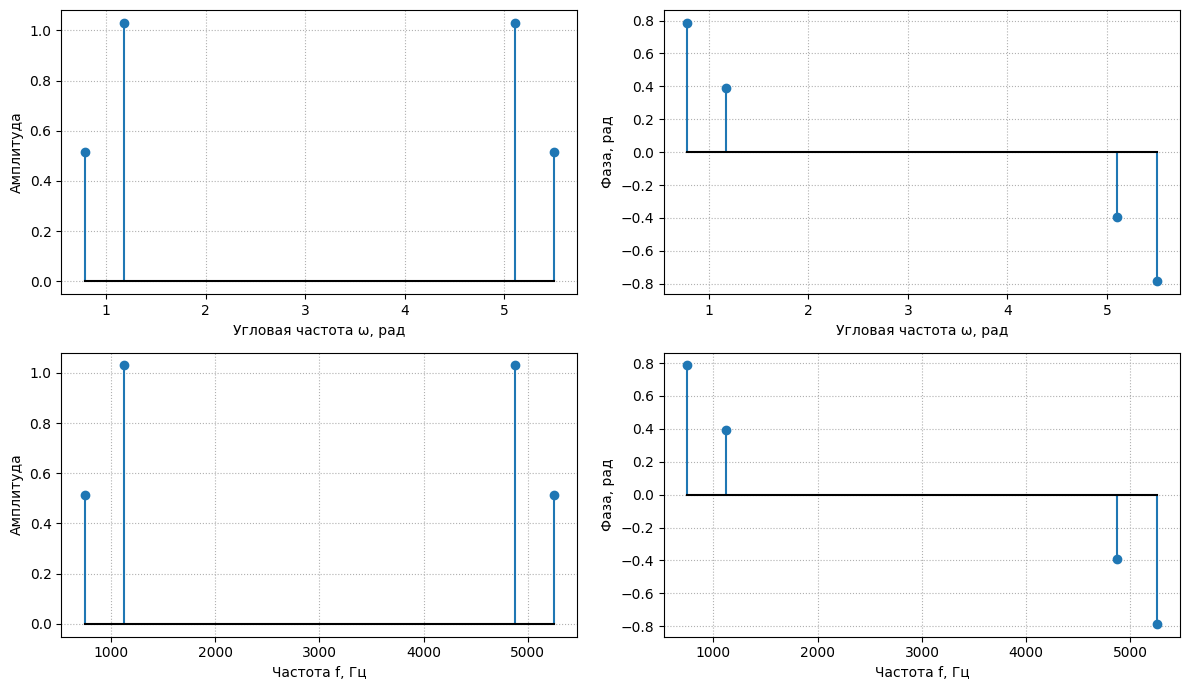

In [101]:
h = np.fft.fft(xn)
k = np.arange(0, N)

# Нормализация на длину сигнала
amp = np.abs(h) / N
phi = np.angle(h)

mask = amp > 1e-8 * np.max(amp)
freq_hz = k * (fd / N) # Абсолютная

peak_indices = np.where(mask)[0]
for k in peak_indices:
    print(f"Индекс k = {k:2d} | Частота f = {freq_hz[k]:7.1f} Гц | Амплитуда = {amp[k]:.3f}")


fig, ax = plt.subplots(2, 2, figsize=(12, 7))

# а спектр (радианы)
ax[0, 0].stem(w[mask], amp[mask], basefmt="k-")
ax[0, 0].grid(True, linestyle=':')
ax[0, 0].set_xlabel("Угловая частота ω, рад")
ax[0, 0].set_ylabel("Амплитуда")
# ф спектр (радианы)
ax[0, 1].stem(w[mask], phi[mask], basefmt="k-")
ax[0, 1].grid(True, linestyle=':')
ax[0, 1].set_xlabel("Угловая частота ω, рад")
ax[0, 1].set_ylabel("Фаза, рад")
# а спектр (Гц)
ax[1, 0].stem(freq_hz[mask], amp[mask], basefmt="k-")
ax[1, 0].grid(True, linestyle=':')
ax[1, 0].set_xlabel("Частота f, Гц")
ax[1, 0].set_ylabel("Амплитуда")
# ф спектр (Гц)
ax[1, 1].stem(freq_hz[mask], phi[mask], basefmt="k-")
ax[1, 1].grid(True, linestyle=':')
ax[1, 1].set_xlabel("Частота f, Гц")
ax[1, 1].set_ylabel("Фаза, рад")

plt.tight_layout()

* a. Дискретное нормированное время - это число отсчётов n. Дискретное время = n⋅T, где T - период дискретизации.
* b. Абсолютная частота f(k) = $\cfrac{k\cdot f_д}{N}$, нормированная частота $\hat\omega = \cfrac{2\pi\cdot f}{f_д} = \cfrac{2\pi\cdot k}{N}$
* c. На амплитудном спектре есть 4 максимума. На 750 Гц и 5250 Гц амплитуда = 0.515, на 1125 и 4875 Гц амплитуда = 1.03. На фазовый спектре видны значения 0.8 и 0.4, это примерно равно $\pi/4$ и $\pi/8$, которыми задаётся последовательность x(nT).  

#### 2.4 Вычислить ДПФ конечной последовательности x(n) длины N. Вывести графики в шкале дискретных нормированных частот модуля ДПФ конечной последовательности и амплитудного спектра периодической последовательности. Пояснить связь модуля ДПФ конечной последовательности с амплитудным спектром периодической последовательности.

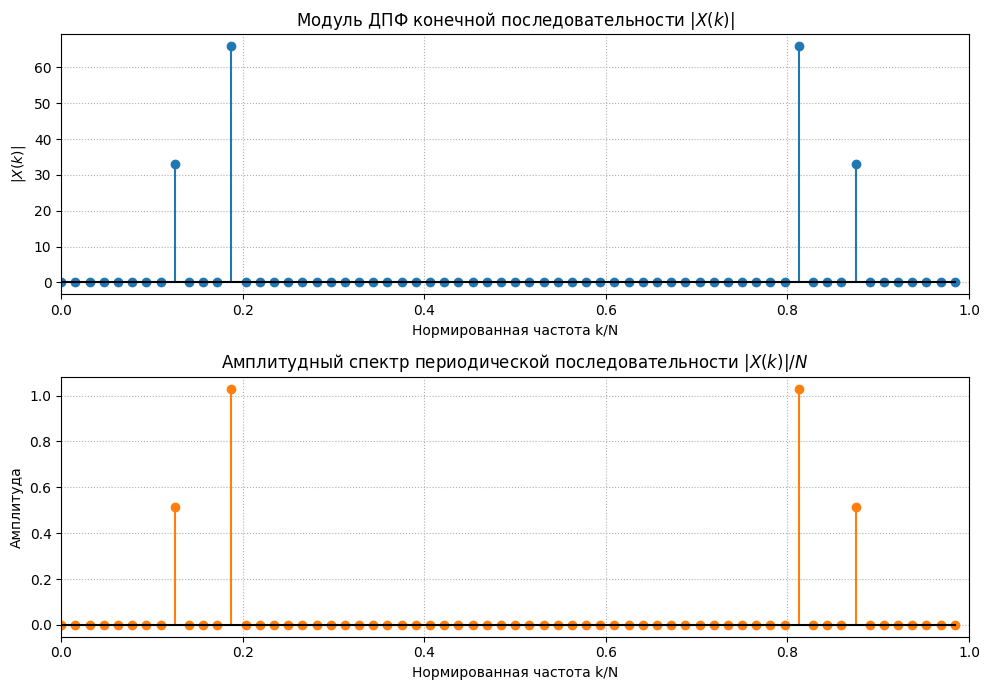

In [107]:
X = np.fft.fft(xn)
X_abs = np.abs(X)

X_periodic = X_abs / N

# Дискретная нормированная частота (k/N)
k = np.arange(N)
f_norm = k / N

fig, ax = plt.subplots(2, 1, figsize=(10, 7))
# Модуль ДПФ конечной последовательности
ax[0].stem(f_norm, X_abs, basefmt="k-", linefmt='C0-', markerfmt='o')
ax[0].set_title('Модуль ДПФ конечной последовательности $|X(k)|$')
ax[0].set_xlabel('Нормированная частота k/N')
ax[0].set_ylabel('$|X(k)|$')
ax[0].grid(True, linestyle=':')
ax[0].set_xlim(0, 1)
# Амплитудный спектр периодической последовательности
ax[1].stem(f_norm, X_periodic, basefmt="k", linefmt='C1-', markerfmt='o')
ax[1].set_title('Амплитудный спектр периодической последовательности $|X(k)|/N$')
ax[1].set_xlabel('Нормированная частота k/N')
ax[1].set_ylabel('Амплитуда')
ax[1].grid(True, linestyle=':')
ax[1].set_xlim(0, 1)

plt.tight_layout()


ОДПФ: $x(n) = \cfrac{1}{N}\sum_{k=0}^{N-1}X(k)e^{2\pi nkj/N}$. x(n) - сумма гармоник. X(k)/N - коэффициент гармоники, её модуль является амплитудой k-ой гармоники.
Модуль ДПФ конечной последовательности и амплитудный спектр связаны: $X_{period}(k) = \cfrac{|X(k)|}{N}$


#### 2.5 Восстановить периодический аналоговый сигнал x(t) по отсчётам ДПФ X(k) периодической последовательности x(n). Для вычисления значений сигнала x(t) использовать формулу:

$$x(t) = \frac{1}{N} \sum_{k=-N/2}^{N/2-1} X_a(k) \exp\left( j\frac{2\pi}{NT} kt \right)$$

где отсчеты $X_a(k)$ связаны с отсчетами ДПФ $X(k)$ соотношением:
$$X_a(k) =
\begin{cases}
X(N + k), & -N/2 \leqslant k \leqslant -1 \\
X(k), & 0 \leqslant k \leqslant N/2 - 1
\end{cases}$$

задавая значения времени t на интервале t $\in [0; (N-1)T]$ с шагом $\delta t = 0.25T$. Вывести графики:
* a. периодической последовательности x(n) и модуля ее ДПФ;
* b. восстановленного аналогового сигнала x(t) и его амплитудного спектра;
* исходного аналогового сигнала x(t) = x(nT)|nT=t

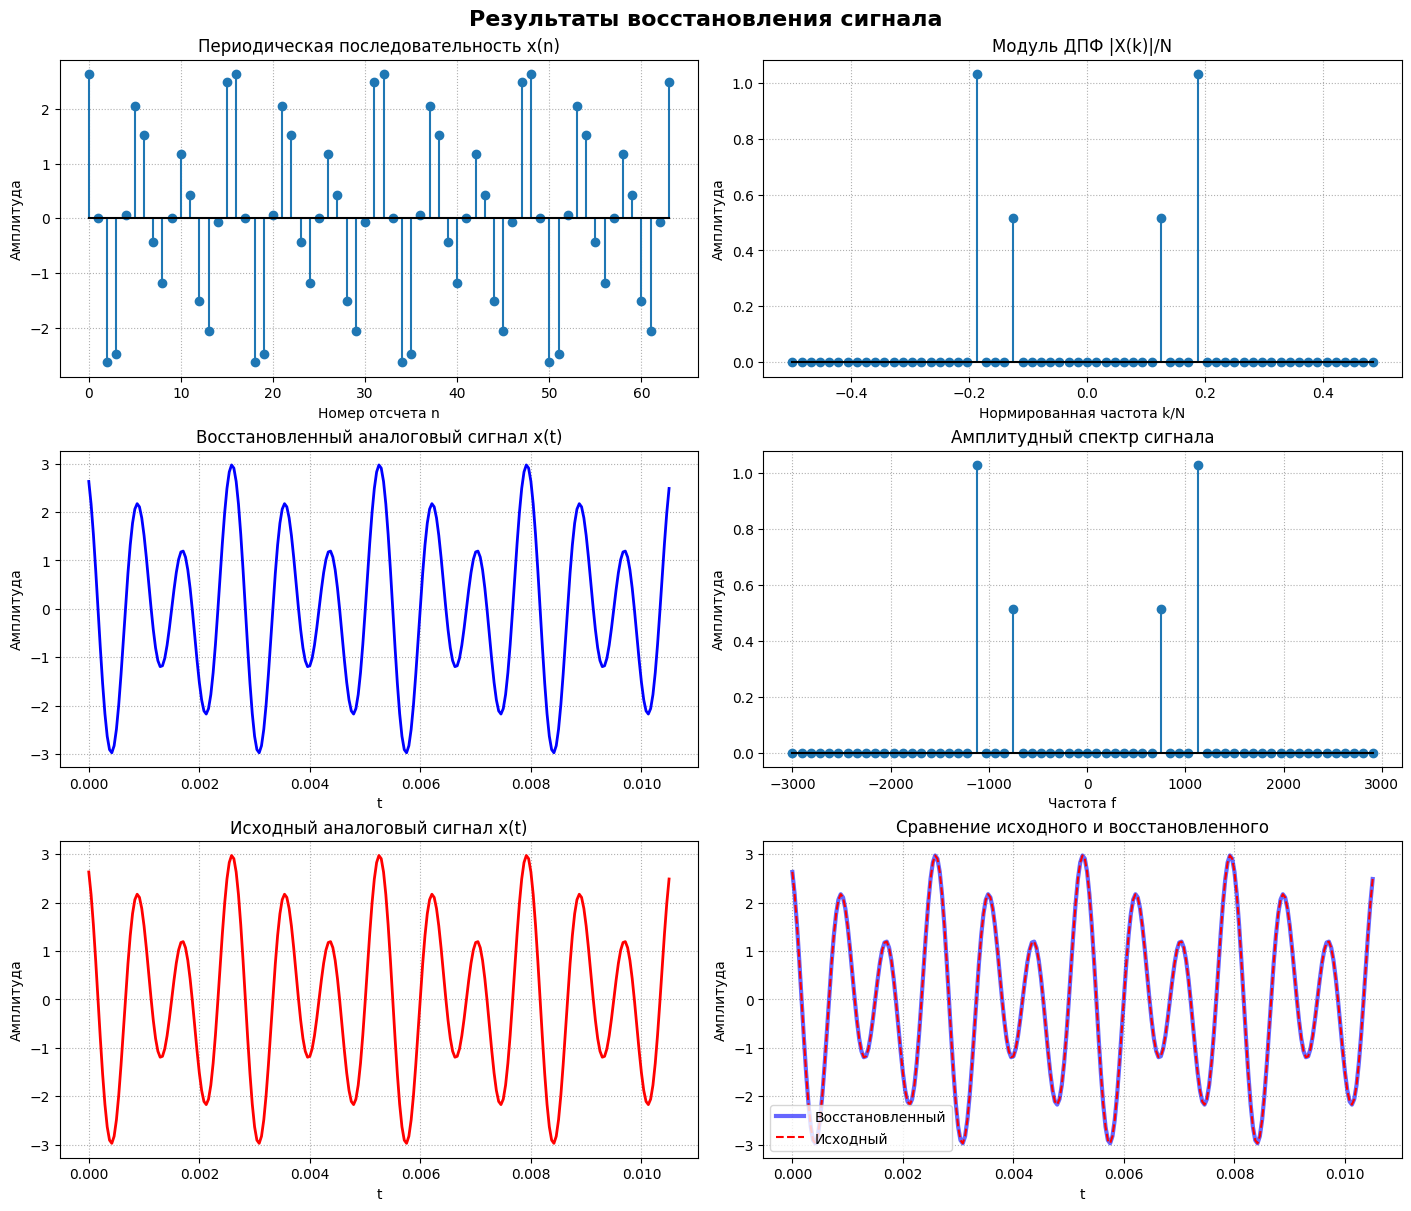

In [113]:
X_a = np.fft.fftshift(X)
k = np.arange(-N//2, N//2)

t = np.arange(0, (N-1)*T + 0.25*T, 0.25*T)

xt_rec = np.zeros_like(t, dtype=complex)
xt_orig = A1 * np.cos(2 * np.pi * f1 * t + np.pi / 4) + \
          A2 * np.cos(2 * np.pi * f2 * t + np.pi / 8)

for i, ti in enumerate(t):
    summation = np.sum(X_a * np.exp(1j * 2 * np.pi / (N * T) * k * ti))
    xt_rec[i] = summation / N

xt_rec = np.real(xt_rec)


fig, axs = plt.subplots(3, 2, figsize=(14, 12), constrained_layout=True)
fig.suptitle('Результаты восстановления сигнала', fontsize=16, fontweight='bold')

axs[0, 0].stem(n, xn, basefmt="k-")
axs[0, 0].set_title('Периодическая последовательность x(n)')
axs[0, 0].set_xlabel('Номер отсчета n')
axs[0, 0].set_ylabel('Амплитуда')
axs[0, 0].grid(True, linestyle=':')

f_norm = k / N
axs[0, 1].stem(f_norm, np.abs(X_a) / N, basefmt="k-")
axs[0, 1].set_title('Модуль ДПФ |X(k)|/N')
axs[0, 1].set_xlabel('Нормированная частота k/N')
axs[0, 1].set_ylabel('Амплитуда')
axs[0, 1].grid(True, linestyle=':')

axs[1, 0].plot(t, xt_rec, 'b-', linewidth=2)
axs[1, 0].set_title('Восстановленный аналоговый сигнал x(t)')
axs[1, 0].set_xlabel('t')
axs[1, 0].set_ylabel('Амплитуда')
axs[1, 0].grid(True, linestyle=':')

freq_hz = k * (fd / N)
axs[1, 1].stem(freq_hz, np.abs(X_a) / N, basefmt="k-")
axs[1, 1].set_title('Амплитудный спектр сигнала')
axs[1, 1].set_xlabel('Частота f')
axs[1, 1].set_ylabel('Амплитуда')
axs[1, 1].grid(True, linestyle=':')

axs[2, 0].plot(t, xt_orig, 'r-', linewidth=2)
axs[2, 0].set_title('Исходный аналоговый сигнал x(t)')
axs[2, 0].set_xlabel('t')
axs[2, 0].set_ylabel('Амплитуда')
axs[2, 0].grid(True, linestyle=':')

axs[2, 1].plot(t, xt_rec, 'b-', linewidth=3, alpha=0.6, label='Восстановленный')
axs[2, 1].plot(t, xt_orig, 'r--', linewidth=1.5, label='Исходный')
axs[2, 1].set_title('Сравнение исходного и восстановленного')
axs[2, 1].set_xlabel('t')
axs[2, 1].set_ylabel('Амплитуда')
axs[2, 1].legend()
axs[2, 1].grid(True, linestyle=':')

#### 2.6 Исходя из результатов п. 5, объяснить:
* a. связь модуля ДПФ последовательности со спектром аналогового сигнала;
* b. результат визуального сравнения восстановленного и исходного сигналов.

* a. При уменьшении шага дискретизации до 0.25T частота дискретизации и диапазон отображаемых частот увеличиваются в 4 раза. Количество отсчетов возрастает до 4N, поэтому модуль ДПФ становится в 4N раз больше амплитудного спектра аналогового сигнала.
* b. Визуально графики исходного и восстановленного полностью совпадают.

#### 2.7 Проверить равенство Парсеваля. Пояснить его смысл.

In [116]:
E_time = np.sum(np.abs(xn)**2)

# Энергия в частотной области (сумма квадратов модулей ДПФ / N)
E_freq = np.sum(np.abs(X_k)**2) / N

print(f"Энергия во времени (E_time): {E_time:.4f}")
print(f"Энергия в частоте (E_freq): {E_freq:.4f}")
print(f"Разница: {np.abs(E_time - E_freq):.2e}")

Энергия во времени (E_time): 169.7440
Энергия в частоте (E_freq): 169.7440
Разница: 2.84e-14


Равенство Парсеваля:

$$\sum_{n=0}^{N-1}|x(n)|^2 = \cfrac{1}{N}\sum_{k=0}^{N-1}|X(k)|^2$$

Теорема Парсеваля устанавливает равенство между энергией сигнала и энергией его спектра.

## Выводы

В ходе лабораторной работы были изучены линейные дискретные системы и дискретное преобразование Фурье. Установлено, что исследуемое звено 2-го порядка является устойчивым рекурсивным БИХ-фильтром с бесконечной импульсной характеристикой; реакции, полученные через свёртку и разностное уравнение, полностью совпали, а расположение нулей и полюсов на z-плоскости наглядно объясняет формирование АЧХ и ФЧХ. С помощью прямого и обратного ДПФ были получены спектры, соответствующие заданным параметрам гармоник, а восстановленный по отсчётам аналоговый сигнал идеально совпал с исходным, что подтверждает выполнение теоремы Котельникова. Проверка теоремы Парсеваля доказала, что энергия сигнала сохраняется при переходе между временной и частотной областями.